Добрый день, это вторая лабораторная по МО ФТИИ.

In [45]:
# Служебные библиотеки и воспроизводимость расчётов.
import os, io, base64, gzip, hashlib, json, warnings, sys
from PIL import Image
import numpy as np
import pandas as pd
import scipy
from scipy import stats
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import sklearn
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, HuberRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.exceptions import ConvergenceWarning
try:
    from IPython.display import display, Markdown
except ImportError:
    display = print
    Markdown = lambda text: text

SEED = 42
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_rows', 60)

In [17]:
raw = pd.read_csv("lab_2.csv", sep = ',')
print('Встроенный датасет: lab_2.csv. Строк:', len(raw), 'Столбцов:', raw.shape[1])

Встроенный датасет: lab_2.csv. Строк: 3424 Столбцов: 23


## 1. Подготовка данных и проверка совпадающих записей

Равные значения измерений не означают, что записи дублируют одно событие. Удаляем только **полные повторы всех полей**, включая ID, дату и станцию. Если один ID имеет разные данные, останавливаем расчёт и требуем проверки источника. События разных дат с одинаковыми измерениями сохраняем и показываем отдельно.

Проверяем типы, пропуски, даты, ключ «станция–дата», диапазоны и календарь. Измерения не округляем для обучения; отрицательные температуры допустимы. Нулевую температуру пара при положительной мощности считаем **подозрительным отсутствующим показанием** и заменяем на NaN — это явная рабочая гипотеза, требующая подтверждения инженерами. Пропуски входов далее заполняются медианой исключительно внутри обучающей части каждого Pipeline. Пропуски выручки не влияют на прогноз мощности. Целевые выбросы не удаляем по ошибке модели и не «исправляем» произвольным делением на 10.

In [3]:
# Полное совпадение записи проверяется до любых преобразований.
full_duplicate_mask = raw.duplicated(keep='first')
d = raw.loc[~full_duplicate_mask].copy()
if d.record_id.duplicated().any():
    raise ValueError('Найдены разные записи с одинаковым record_id: нужен аудит источника.')

d['measurement_date'] = pd.to_datetime(d['measurement_date'], errors='raise')
d = d.sort_values(['measurement_date', 'plant_id']).reset_index(drop=True)
assert not d.duplicated(['plant_id', 'measurement_date']).any(), 'Несколько событий на одну дату станции.'

# Только измерительные поля и метаданные; цель и выручка в сравнении не участвуют.
numeric_measurements = [c for c in raw.select_dtypes('number')
                        if c not in ['net_power_output', 'daily_revenue_rub']]
same_values = d.duplicated(numeric_measurements, keep=False)
groups_equal = d.loc[same_values].groupby(numeric_measurements, dropna=False).size()
missing_before = d.isna().sum()
zero_steam = d.steam_temperature.eq(0) & d.net_power_output.gt(0)
d.loc[zero_steam, 'steam_temperature'] = np.nan

# создаём таблицу, для визуального просмотра
audit = pd.DataFrame({'Показатель': [
    'Строк исходно', 'Полных лишних повторов удалено', 'Строк после обработки',
    'Станций', 'Групп одинаковых числовых измерений при разных ID/датах',
    'Сохранено строк в таких группах', 'Нулевых температур пара помечено NaN'],
    'Значение': [len(raw), int(full_duplicate_mask.sum()), len(d), d.plant_id.nunique(),
                 len(groups_equal), int(same_values.sum()), int(zero_steam.sum())]})
display(audit)
print('Период:', d.measurement_date.min().date(), '—', d.measurement_date.max().date())
missing_table = pd.DataFrame({'До обработки': missing_before, 'После обработки': d.isna().sum()})
display(missing_table.loc[missing_table.max(axis=1).gt(0)])
display(d.loc[same_values, ['record_id', 'measurement_date', 'plant_id', 'net_power_output']].head(12))

# Не меняем числовые диапазоны без первичного подтверждения ошибки измерения.
display(d.select_dtypes('number').describe().T[['min', '50%', 'max']].round(2))
weekday_names = {0:'Пн',1:'Вт',2:'Ср',3:'Чт',4:'Пт',5:'Сб',6:'Вс'}
date_weekday = d.measurement_date.dt.dayofweek.map(weekday_names)
print('Несовпадений day_of_week с календарной датой:', int((d.day_of_week.str.strip() != date_weekday).sum()))
print('Цель без пропусков:', bool(d.net_power_output.notna().all()))

,Показатель,Значение
0,Строк исходно,3424
1,Полных лишних повторов удалено,12
2,Строк после обработки,3412
3,Станций,40
4,Групп одинаковых числовых измерений при разных...,10
5,Сохранено строк в таких группах,20
6,Нулевых температур пара помечено NaN,73


Период: 2024-09-02 — 2026-08-31


,До обработки,После обработки
ambient_pressure,102,102
steam_temperature,150,223
daily_revenue_rub,87,87


,record_id,measurement_date,plant_id,net_power_output
66,REC-102068,2024-09-15,PLANT-17,421.85
530,REC-102535,2024-12-22,PLANT-33,337.84
713,REC-100685,2025-02-02,PLANT-21,403.70
778,REC-100188,2025-02-16,PLANT-23,300.86
900,REC-103408,2025-03-15,PLANT-21,403.70
1293,REC-100932,2025-06-04,PLANT-37,249.90
1499,REC-101620,2025-07-17,PLANT-40,487.92
1524,REC-103018,2025-07-25,PLANT-08,300.44
1541,REC-101734,2025-07-29,PLANT-23,264.69
1607,REC-100242,2025-08-11,PLANT-37,249.90


,min,50%,max
ambient_temperature,-8.72,17.84,42.00
ambient_pressure,992.70,1012.90,1032.80
relative_humidity,25.10,60.85,95.00
exhaust_vacuum,30.00,53.76,82.00
turbine_load,30.02,64.98,99.99
fuel_flow_rate,3.00,12.57,23.12
fuel_calorific_value,35.00,42.09,48.00
steam_pressure,63.34,111.50,159.60
steam_temperature,390.50,503.90,624.20
condenser_temperature,2.32,29.66,57.58


Несовпадений day_of_week с календарной датой: 0
Цель без пропусков: True


**Решение о повторах:** полные повторные записи удалены. Совпадающие измерения разных событий сохранены. Их происхождение желательно проверить: если источник подтвердит копирование одного события, необходимо объединить записи или держать их в одной группе при оценке. Пока нет такого подтверждения, разные даты не объявляются дублями.

## 2. Отбор признаков с учётом момента прогноза

Нельзя подавать фактическую нагрузку, расход топлива или температуру **целевых суток**: накануне они ещё неизвестны. Вместо них используем последнее историческое измерение той же станции. Известный заранее план нагрузки и прогноз погоды были бы допустимы, но таких полей в CSV нет.

| Поле | Использование |
|---|---|
| `net_power_output` целевого дня | Только y |
| Прошлая `net_power_output` | Разрешена при своевременной публикации; обязательный учёт мощности сохраняется |
| `daily_revenue_rub` | Исключена: итоговая выручка связана с целевым результатом |
| `generator_efficiency` | Исключён как потенциально вычисляемый через мощность |
| 14 измерительных полей | Только исторические версии с префиксом `past_` |
| `maintenance_days_since_last` | Исторические метаданные, не отдельный датчик |
| `plant_id` | Категория для прогноза на тех же станциях |
| Целевая дата | Известные заранее день недели и годовой цикл |
| `record_id` | Аудит и связывание строк, не вход модели |
| `operator_shift` целевого дня | Исключена: доступность расписания накануне не подтверждена |
| `day_of_week` | Пересчитывается по целевой дате |

`merge_asof` берёт строго более раннюю дату **внутри той же станции**. Это не сдвиг на «следующую строку»: расстояние между строками бывает больше суток. Если последнее измерение сделано шесть дней назад, оно остаётся шестидневной историей для целевой даты; её возраст явно передаётся модели.

In [33]:
# Допустим, что каждый датчик считается отдельным необязательным датчиком.
# В реестре соответствие столбца физическому прибору нужно проверить.
sensors = [c for c in numeric_measurements
           if c not in ['generator_efficiency', 'maintenance_days_since_last']]
assert len(sensors) == 14
right_fields = sensors + ['maintenance_days_since_last', 'net_power_output']
history = d[['measurement_date', 'plant_id'] + right_fields].rename(columns={
    'measurement_date':'source_date', **{c:'past_'+c for c in right_fields}})
left = d[['record_id', 'measurement_date', 'plant_id', 'net_power_output']]
data = pd.merge_asof(left.sort_values('measurement_date'), history.sort_values('source_date'),
                    left_on='measurement_date', right_on='source_date', by='plant_id',
                    direction='backward', allow_exact_matches=False)
no_history = int(data.source_date.isna().sum())
data = data.dropna(subset=['source_date']).sort_values(['measurement_date','plant_id']).reset_index(drop=True)
assert (data.source_date < data.measurement_date).all()
data['history_age_days'] = (data.measurement_date - data.source_date).dt.days
# Работаем с месяцами, переводим даты в круг, чтоб раставить месяца
data['weekday'] = data.measurement_date.dt.dayofweek.astype(str)
data['month_sin'] = np.sin(2*np.pi*(data.measurement_date.dt.month-1)/12)
data['month_cos'] = np.cos(2*np.pi*(data.measurement_date.dt.month-1)/12)
# Более точный непрерывный календарь зарезервирован для доработки пункта 7.
year_length = np.where(data.measurement_date.dt.is_leap_year,366,365)
day_phase = 2*np.pi*(data.measurement_date.dt.dayofyear-1)/year_length
for harmonic in [1,2]:
    data[f'day_sin{harmonic}'] = np.sin(harmonic*day_phase)
    data[f'day_cos{harmonic}'] = np.cos(harmonic*day_phase)
base_numeric = ['past_net_power_output', 'past_maintenance_days_since_last',
                'history_age_days', 'month_sin', 'month_cos']
sensor_inputs = ['past_'+c for c in sensors]
full_numeric = base_numeric + sensor_inputs
categorical = ['plant_id', 'weekday']

# Заготовка на будущее
# Она подготовлена только из прошлых значений и будет проверена в пункте 7.
derived = pd.DataFrame(index=d.index)
for plant, group in d.groupby('plant_id', sort=False):
    p = group.net_power_output.shift(1)  # текущая цель в историю не попадает
    derived.loc[group.index, 'power_mean3'] = p.rolling(3, min_periods=1).mean()
    derived.loc[group.index, 'power_median3'] = p.rolling(3, min_periods=1).median()
    derived.loc[group.index, 'power_std3'] = p.rolling(3, min_periods=2).std()
    derived.loc[group.index, 'power_change'] = p - group.net_power_output.shift(2)
# Сводим таблицы 
derived['record_id'] = d.record_id
data = data.merge(derived, on='record_id', how='left', validate='one_to_one')
engineered_numeric = full_numeric + ['power_mean3','power_median3','power_std3','power_change']
seasonal_numeric = [c for c in full_numeric if c not in ['month_sin','month_cos']] + [
    'day_sin1','day_cos1','day_sin2','day_cos2']

print('Исключено первых наблюдений станций без истории:', no_history)
print('Строго более ранняя история проверена для всех', len(data), 'строк.')
display(data.history_age_days.describe().to_frame('Возраст истории, дней').round(2))
display(data[['record_id','plant_id','measurement_date','source_date','history_age_days']].head(8))

Исключено первых наблюдений станций без истории: 40
Строго более ранняя история проверена для всех 3372 строк.


,"Возраст истории, дней"
count,3372.00
mean,8.48
std,8.12
min,1.00
25%,3.00
50%,6.00
75%,12.00
max,75.00


,record_id,plant_id,measurement_date,source_date,history_age_days
0,REC-100206,PLANT-06,2024-09-03,2024-09-02,1
1,REC-103196,PLANT-06,2024-09-04,2024-09-03,1
2,REC-102647,PLANT-36,2024-09-05,2024-09-02,3
3,REC-102324,PLANT-32,2024-09-06,2024-09-04,2
4,REC-100501,PLANT-23,2024-09-07,2024-09-06,1
5,REC-100023,PLANT-32,2024-09-07,2024-09-06,1
6,REC-101820,PLANT-31,2024-09-08,2024-09-06,2
7,REC-102185,PLANT-06,2024-09-09,2024-09-04,5


## 3. Схема валидации

Датасет — **разреженная панель из 40 станций во времени**. Проверяем будущие даты для уже известных станций. Последние 20% уникальных исходных дат — временной тест. Одинаковая дата всех станций всегда находится в одной части. Случайное перемешивание не соответствует применению модели на будущих сутках.

На обучающем периоде используем пять окон с расширением обучения. `TimeSeriesSplit` применяется к **полной календарной сетке**, затем даты переводятся в индексы строк. Это сохраняет сопоставимую длительность окон при пропусках дней. Импутация, масштабирование, кодирование категорий и отбор Lasso выполняются внутри соответствующего обучения.

Моделируется ежедневный скользящий прогноз: при переходе к следующей дате разрешено получить уже опубликованные итоги предыдущих дат, в том числе внутри тестового периода. **Параметры модели при этом на тесте не переобучаются.** Это отличается от прогноза всех будущих месяцев одним запуском.

Разрыв `gap=0` допустим только при принятом предположении, что предыдущий итог опубликован до выдачи прогноза. При задержке публикации или перекрытии периодов целей нужен разрыв и отбор по `available_at`. Для новых станций дополнительно потребуется отдельная групповая проверка. Лучшие значения CV после подбора являются оценками для выбора, а не независимыми итоговыми метриками.

In [19]:
# Делим данные по датам, старые на обучение, новые на тест 
unique_dates = np.sort(d.measurement_date.unique())
cutoff = pd.Timestamp(unique_dates[int(0.8*len(unique_dates))])
train = data.loc[data.measurement_date < cutoff].reset_index(drop=True)
test = data.loc[data.measurement_date >= cutoff].reset_index(drop=True)
assert train.measurement_date.max() < test.measurement_date.min()
assert set(test.plant_id).issubset(set(train.plant_id))

def time_splits(frame, n_splits=5):
    """Делим календарь, а затем выбираем все станции соответствующих дат."""
    days = pd.date_range(frame.measurement_date.min(), frame.measurement_date.max(), freq='D')
    result = []
    for tr_days, va_days in TimeSeriesSplit(n_splits=n_splits).split(days):
        tr_idx = np.flatnonzero(frame.measurement_date.isin(days[tr_days]))
        va_idx = np.flatnonzero(frame.measurement_date.isin(days[va_days]))
        assert frame.iloc[tr_idx].measurement_date.max() < frame.iloc[va_idx].measurement_date.min()
        result.append((tr_idx, va_idx))
    return result

cv = time_splits(train)
fold_table = []
for i, (tr_idx, va_idx) in enumerate(cv, 1):
    tr, va = train.iloc[tr_idx], train.iloc[va_idx]
    fold_table.append({'Окно':i, 'Обучение с':tr.measurement_date.min().date(),
        'Обучение по':tr.measurement_date.max().date(), 'Проверка с':va.measurement_date.min().date(),
        'Проверка по':va.measurement_date.max().date(), 'N обучения':len(tr), 'N проверки':len(va)})
display(pd.DataFrame(fold_table))
print('Итоговое обучение:', len(train), '| Тест:', len(test), '| Начало теста:', cutoff.date())

def make_preprocessor(cols):
    # Все статистики преобразований оцениваются только при fit Pipeline.
    # Также работает с пропусками и кодируем категории
    return ColumnTransformer([
        ('num', Pipeline([('fill',SimpleImputer(strategy='median')), ('scale',StandardScaler())]), cols),
        ('cat', OneHotEncoder(drop='first',handle_unknown='ignore',sparse_output=False), categorical)])

def make_model(cols, estimator):
    return Pipeline([('pre',make_preprocessor(cols)), ('reg',estimator)])

# Анализ метрик
def metric_values(y, prediction):
    return {'MAE':float(mean_absolute_error(y,prediction)),
            'RMSE':float(np.sqrt(mean_squared_error(y,prediction))),
            'R2':float(r2_score(y,prediction))}

def fit_search(estimator, grid, frame=train, splits=None):
    """Подбор по MAE. Предупреждение сходимости считаем поводом исправить модель."""
    search = GridSearchCV(estimator, grid, scoring='neg_mean_absolute_error',
                          cv=(cv if splits is None else splits), n_jobs=1,
                          refit=True, error_score='raise', return_train_score=False)
    with warnings.catch_warnings(record=True) as notices:
        warnings.simplefilter('always')
        search.fit(frame, frame.net_power_output)
    convergence = [str(w.message) for w in notices if issubclass(w.category,ConvergenceWarning)]
    if convergence:
        raise RuntimeError('Не достигнута сходимость: '+convergence[0])
    unexpected = [str(w.message) for w in notices
                  if not ('Found unknown categories' in str(w.message))]
    if unexpected:
        print('Дополнительные сообщения:', sorted(set(unexpected)))
    return search

def oof_predictions(estimator, frame=train, splits=cv):
    """Прогнозы только для строк, не участвовавших в обучении данного окна."""
    out = np.full(len(frame), np.nan)
    for tr_idx, va_idx in splits:
        fitted = clone(estimator).fit(frame.iloc[tr_idx], frame.iloc[tr_idx].net_power_output)
        out[va_idx] = fitted.predict(frame.iloc[va_idx])
    return out

models, predictions, summaries = {}, {}, []
def readable_params(params):
    return {key:(value.item() if isinstance(value,np.generic) else value)
            for key,value in (params or {}).items()}

def register(name, estimator, cols, cv_mae=np.nan, params=None):
    models[name] = estimator
    predictions[name] = estimator.predict(test)
    summaries.append({'Модель':name, 'Датчиков':len([c for c in sensor_inputs if c in cols]),
                      'CV_MAE_подбор':cv_mae, **metric_values(test.net_power_output,predictions[name]),
                      'Параметры':str(readable_params(params))})

,Окно,Обучение с,Обучение по,Проверка с,Проверка по,N обучения,N проверки
0,1,2024-09-03,2024-12-11,2024-12-12,2025-03-17,434,442
1,2,2024-09-03,2025-03-17,2025-03-18,2025-06-21,876,462
2,3,2024-09-03,2025-06-21,2025-06-22,2025-09-25,1338,426
3,4,2024-09-03,2025-09-25,2025-09-26,2025-12-30,1764,458
4,5,2024-09-03,2025-12-30,2025-12-31,2026-04-05,2222,455


Итоговое обучение: 2677 | Тест: 695 | Начало теста: 2026-04-06


## 4. Диагностика мультиколлинеарности

Смотрим корреляции и VIF **на обучении**, для реально используемых исторических входов. VIF показывает, насколько вход объясняется остальными: (VIF_j=1/(1-R_j^2)). Значения выше 5–10 — ориентиры для проверки, а не автоматическое основание отключать прибор. Для корреляций показываем пары с (|r|>0.9).

Диагностическая импутация ниже обучается только на train и не заменяет импутацию в модельных Pipeline. Проверяем также ранг и обусловленность всей стандартизованной матрицы, включая категориальные входы. Исключаем одну категорию каждой группы one-hot; иначе константа и все индикаторы дали бы точную зависимость.

,Признак 1,Признак 2,Корреляция
0,past_net_power_output,past_turbine_load,0.942
1,past_net_power_output,past_steam_pressure,0.932
2,past_net_power_output,past_air_intake_flow,0.932
3,past_ambient_temperature,past_condenser_temperature,0.908
4,past_ambient_temperature,past_cooling_water_flow,0.936
5,past_ambient_temperature,past_compressor_inlet_temp,0.995
6,past_turbine_load,past_fuel_flow_rate,0.929
7,past_turbine_load,past_steam_pressure,0.992
8,past_turbine_load,past_steam_temperature,0.939
9,past_turbine_load,past_air_intake_flow,0.989


,Признак,VIF
0,past_turbine_load,124.43
1,past_ambient_temperature,113.62
2,past_compressor_inlet_temp,93.23
3,past_steam_pressure,70.75
4,past_air_intake_flow,45.97
5,past_condenser_temperature,15.11
6,past_net_power_output,13.56
7,past_fuel_flow_rate,11.12
8,past_steam_temperature,9.92
9,past_cooling_water_flow,8.13


Матрица с константой: (2677, 65) | Ранг: 65 | Число обусловленности: 92.68


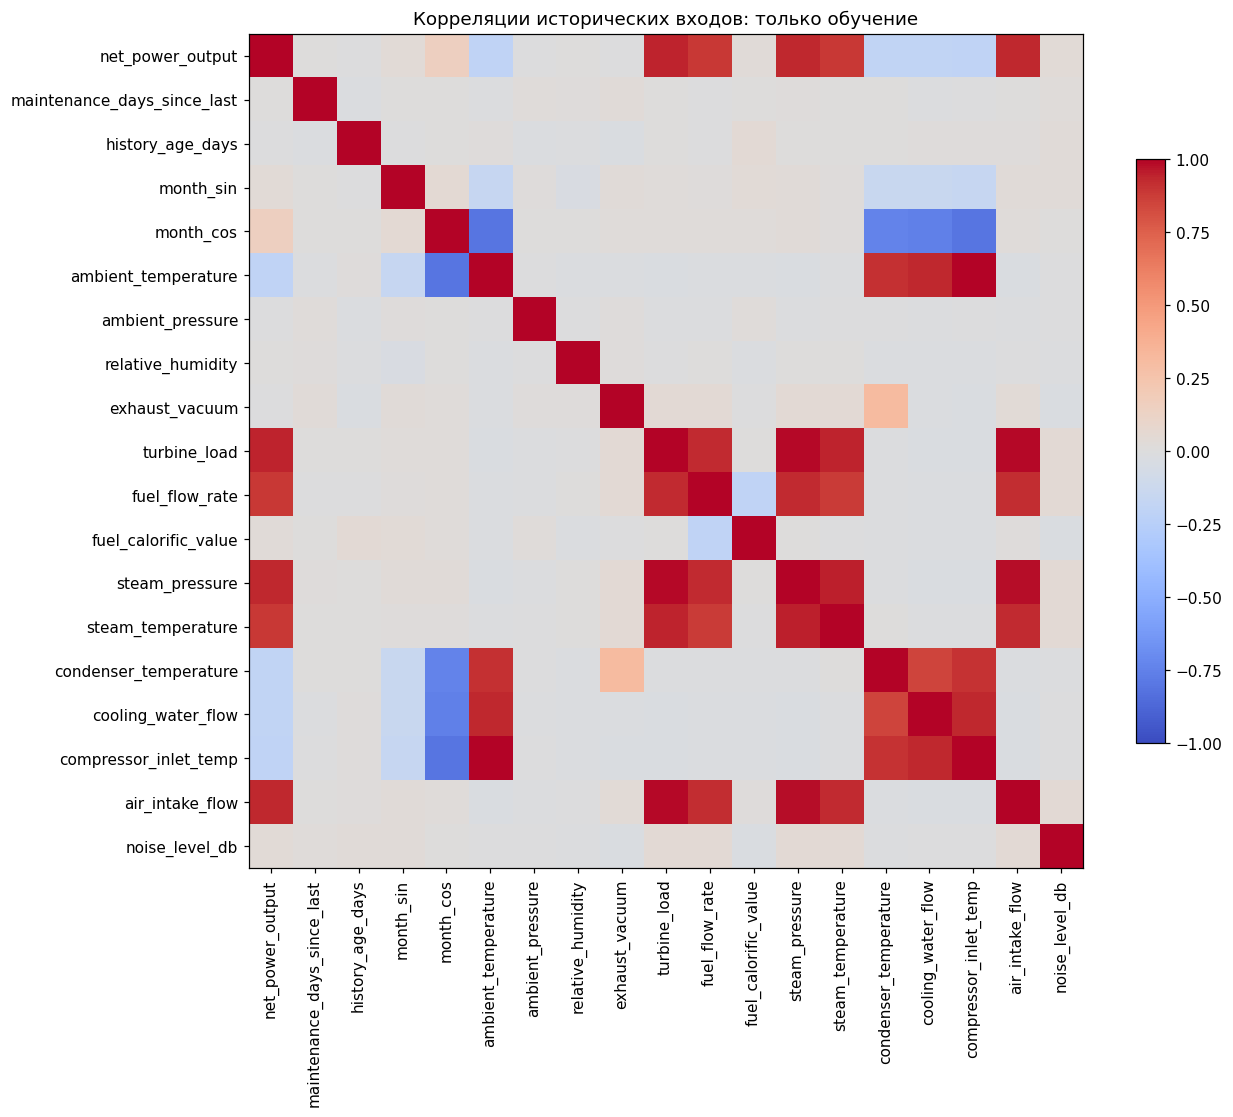

In [34]:
# Заполняем пропуски, вычисление попарных корреляций
diagnostic_fill = SimpleImputer(strategy='median')
filled = pd.DataFrame(diagnostic_fill.fit_transform(train[full_numeric]), columns=full_numeric)
corr = filled.corr()
pairs = [{'Признак 1':a, 'Признак 2':b, 'Корреляция':float(corr.loc[a,b])}
         for i,a in enumerate(full_numeric) for b in full_numeric[i+1:]
         if abs(corr.loc[a,b])>0.9]
strong_pairs = pd.DataFrame(pairs, columns=['Признак 1','Признак 2','Корреляция'])
display(strong_pairs.round(3))

#Сильные корреляции и вспомогательные
def vif_table(frame):
    rows = []
    for column in frame:
        other = frame.drop(columns=column)
        r2 = LinearRegression().fit(other,frame[column]).score(other,frame[column])
        vif = np.inf if 1-r2<1e-10 else 1/(1-r2)
        rows.append({'Признак':column,'VIF':vif})
    return pd.DataFrame(rows).sort_values('VIF',ascending=False).reset_index(drop=True)

vif = vif_table(filled)
display(vif.round(2))
diagnostic_pre = make_preprocessor(full_numeric).fit(train)
design = diagnostic_pre.transform(train)
design_with_intercept = np.column_stack([np.ones(len(design)),design])
print('Матрица с константой:', design_with_intercept.shape,
      '| Ранг:', np.linalg.matrix_rank(design_with_intercept),
      '| Число обусловленности:', round(float(np.linalg.cond(design_with_intercept)),2))

# создаём тепловую карт для наглядности
fig, ax = plt.subplots(figsize=(12,10))
im = ax.imshow(corr, cmap='coolwarm', vmin=-1,vmax=1)
short_names = [c.replace('past_','') for c in full_numeric]
ax.set_xticks(range(len(full_numeric)),short_names,rotation=90)
ax.set_yticks(range(len(full_numeric)),short_names)
ax.set_title('Корреляции исторических входов: только обучение')
fig.colorbar(im,ax=ax,shrink=0.7)
plt.tight_layout(); plt.show()

In [21]:
high_vif = vif.loc[vif.VIF>10, 'Признак'].tolist()
display(Markdown('**Вывод шага 4.** Входов с VIF > 10: **'+str(len(high_vif))+
    '**. Высокий VIF означает избыточность между входами, но не доказывает отсутствие '+
    'прогностической пользы. На следующем шаге все входы сохраняются для базовой OLS; '+
    'Ridge проверяет стабилизацию коэффициентов, а Lasso — сокращение набора. '+
    'Удаление датчиков оцениваем отдельным переобучением и сравнением ошибок.'))

**Вывод шага 4.** Входов с VIF > 10: **8**. Высокий VIF означает избыточность между входами, но не доказывает отсутствие прогностической пользы. На следующем шаге все входы сохраняются для базовой OLS; Ridge проверяет стабилизацию коэффициентов, а Lasso — сокращение набора. Удаление датчиков оцениваем отдельным переобучением и сравнением ошибок.

## 5. Базовая модель: линейная регрессия без регуляризации

`LinearRegression()` — метод наименьших квадратов с константой **без штрафа на коэффициенты**. Стандартизация входов не является регуляризацией. Метрики на тесте: **MAE** — средняя абсолютная ошибка в МВт, **RMSE** — ошибка с повышенным весом крупных промахов, **R²** — качество относительно среднего целевого значения теста.

Добавляем ориентиры: среднее обучения, медиану обучения и последний известный уровень мощности станции. Они помогают понять, есть ли у сложной модели реальная прогностическая ценность.

In [35]:
# Модель с обычной LinearRegression и обучаемая на train
ols = make_model(full_numeric, LinearRegression()).fit(train,train.net_power_output)
ols_oof = oof_predictions(make_model(full_numeric,LinearRegression()))
oof_mask = np.isfinite(ols_oof)
ols_cv_mae = mean_absolute_error(train.loc[oof_mask,'net_power_output'],ols_oof[oof_mask])
register('OLS — все датчики',ols,full_numeric,ols_cv_mae)
for strategy, label in [('mean','Ориентир — среднее'),('median','Ориентир — медиана')]:
    estimator = DummyRegressor(strategy=strategy).fit(train[['history_age_days']],train.net_power_output)
    register(label,estimator,[],np.nan,{'strategy':strategy})
predictions['Ориентир — последнее значение'] = test.past_net_power_output.to_numpy()
summaries.append({'Модель':'Ориентир — последнее значение','Датчиков':0,'CV_MAE_подбор':np.nan,
    **metric_values(test.net_power_output,predictions['Ориентир — последнее значение']), 'Параметры':'{}'})
# выводим для визуального осмотра и сравнения
display(pd.DataFrame(summaries)[['Модель','MAE','RMSE','R2']].round(3))

,Модель,MAE,RMSE,R2
0,OLS — все датчики,73.501,92.112,-0.001
1,Ориентир — среднее,74.143,93.436,-0.030
2,Ориентир — медиана,74.332,93.735,-0.036
3,Ориентир — последнее значение,103.313,132.446,-1.069
4,Ridge — все датчики,73.437,91.670,0.009
5,Lasso — все датчики,73.229,91.532,0.012
6,ElasticNet — все датчики,73.439,91.836,0.005
7,Ridge — отбор Lasso,73.245,91.590,0.011
8,Ridge — без необязательных датчиков,73.245,91.590,0.011
9,Ridge — непрерывный календарь,73.455,91.721,0.008


### Анализ остатков

Остаток (e=y-widehat y): положительное значение означает недооценку мощности, отрицательное — завышенный прогноз. На графиках ищем смещение, нелинейную зависимость, неодинаковый разброс и тяжёлые хвосты. Q–Q проверяет форму распределения; нормальность не требуется для вычисления MAE, но важна для стандартных интервалов OLS.

Для выбора доработок используем **OOF-остатки только обучающего периода**: каждая точка получена моделью, которая не видела её дату при обучении. Тестовые остатки ниже — отдельный отчёт по заданию; параметры по ним не подбираются. Последовательные ошибки одной станции при пропусках дат нельзя считать обычным ежедневным рядом.

,OOF обучение,Тест
N,2243.000,695.000
"Средний остаток, МВт",1.249,-0.369
"Медиана остатка, МВт",-0.308,-0.432
"MAE, МВт",71.962,73.501
"RMSE, МВт",85.381,92.112
"90% квантиль |ошибки|, МВт",130.906,130.459
"95% квантиль |ошибки|, МВт",146.418,144.022
"Максимум |ошибки|, МВт",344.899,826.530
Эксцесс остатков,-0.636,8.518


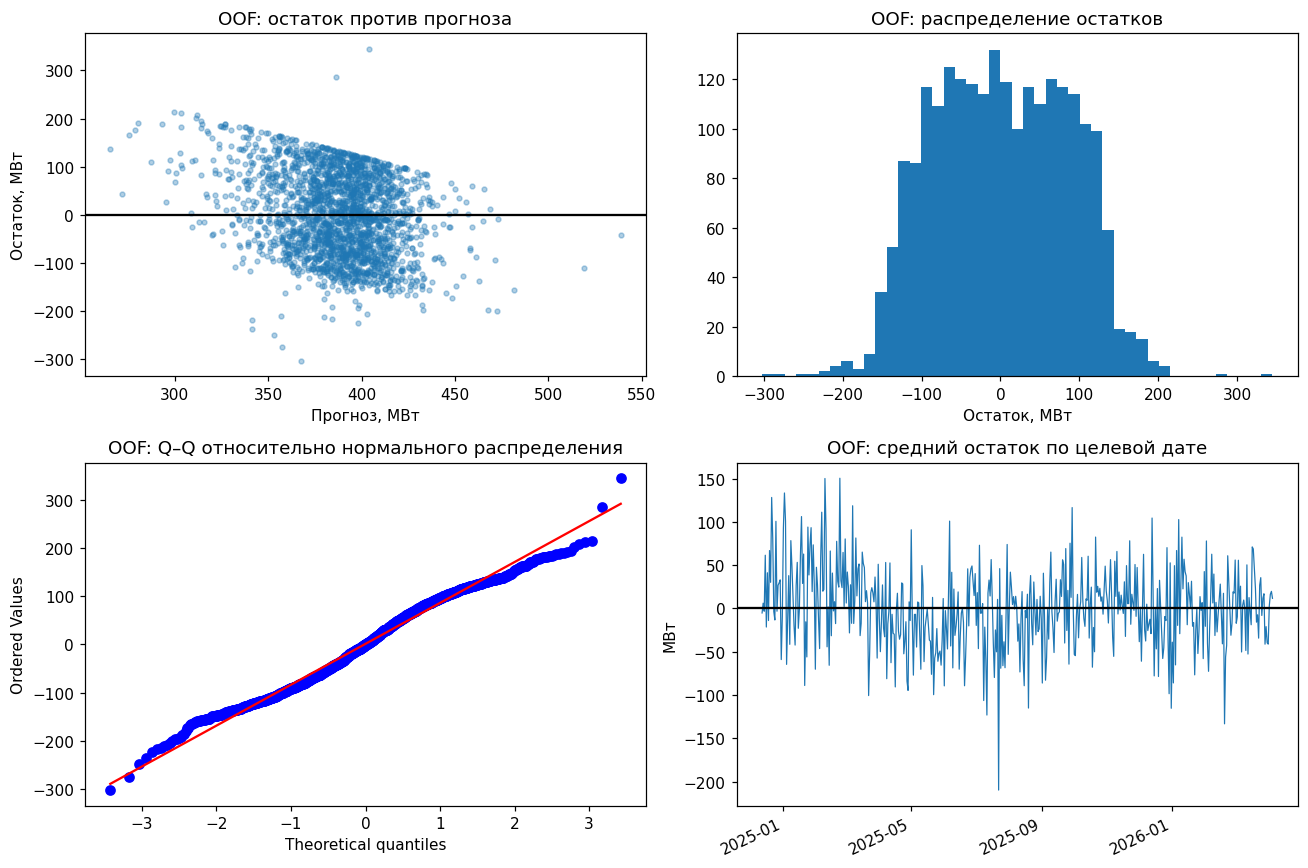

,N,Средний_остаток,MAE
age_group,,,
"(-0.001, 1.0]",274,9.542,75.155
"(1.0, 3.0]",435,4.409,71.670
"(3.0, 7.0]",568,0.746,71.355
"(7.0, 14.0]",581,-3.350,70.874
"(14.0, inf]",385,-0.543,72.557


,N,Средний_остаток,MAE
month,,,
1,277,19.195,71.835
2,268,13.779,75.010
3,302,6.206,69.235
4,166,-16.208,71.809
5,141,-23.738,70.952
6,152,-12.308,76.530
7,128,-21.638,84.342
8,140,-6.072,70.861
9,126,0.516,71.349


,N,Средний_остаток,MAE
plant_id,,,
PLANT-35,60,21.978,85.898
PLANT-01,57,13.545,85.099
PLANT-17,63,18.310,82.598
PLANT-23,45,9.471,81.889
PLANT-30,51,36.408,81.624
PLANT-25,42,-1.173,79.645
PLANT-07,57,11.202,78.861
PLANT-03,63,-18.460,78.503
PLANT-14,50,-18.194,77.966


Корреляция остатков соседних доступных событий станции: 0.075


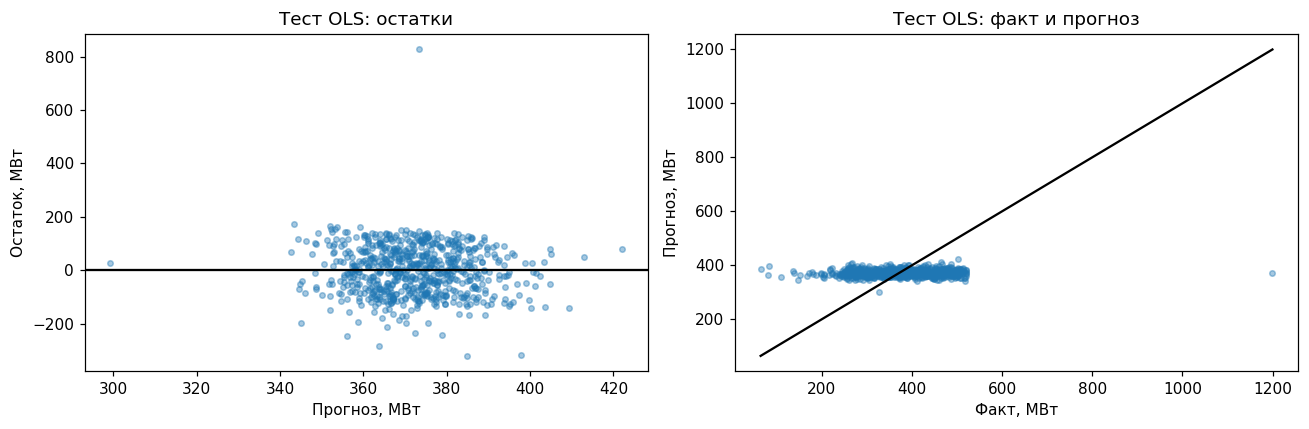

In [36]:
# Обрабатываем ошибки модели
oof = train.loc[oof_mask].copy()
oof['prediction'] = ols_oof[oof_mask]
oof['residual'] = oof.net_power_output-oof.prediction
oof['abs_error'] = oof.residual.abs()
test_res = test.copy()
test_res['prediction'] = predictions['OLS — все датчики']
test_res['residual'] = test_res.net_power_output-test_res.prediction
test_res['abs_error'] = test_res.residual.abs()

# Получаем тестовые ошибки
def residual_report(frame):
    return pd.Series({'N':len(frame), 'Средний остаток, МВт':frame.residual.mean(),
        'Медиана остатка, МВт':frame.residual.median(), 'MAE, МВт':frame.abs_error.mean(),
        'RMSE, МВт':np.sqrt(np.mean(frame.residual**2)),
        '90% квантиль |ошибки|, МВт':frame.abs_error.quantile(.9),
        '95% квантиль |ошибки|, МВт':frame.abs_error.quantile(.95),
        'Максимум |ошибки|, МВт':frame.abs_error.max(),
        'Эксцесс остатков':stats.kurtosis(frame.residual,bias=False)})
display(pd.DataFrame({'OOF обучение':residual_report(oof), 'Тест':residual_report(test_res)}).round(3))

# Визуализируем ошибки
fig,axs = plt.subplots(2,2,figsize=(12,8))
axs[0,0].scatter(oof.prediction,oof.residual,s=10,alpha=.35)
axs[0,0].axhline(0,color='black');axs[0,0].set(xlabel='Прогноз, МВт',ylabel='Остаток, МВт',title='OOF: остаток против прогноза')
axs[0,1].hist(oof.residual,bins=45);axs[0,1].set(title='OOF: распределение остатков',xlabel='Остаток, МВт')
stats.probplot(oof.residual,dist='norm',plot=axs[1,0]);axs[1,0].set_title('OOF: Q–Q относительно нормального распределения')
daily = oof.groupby('measurement_date').residual.mean()
axs[1,1].plot(daily.index,daily.values,lw=.8);axs[1,1].axhline(0,color='black')
axs[1,1].set(title='OOF: средний остаток по целевой дате',ylabel='МВт')
axs[1,1].xaxis.set_major_locator(mdates.AutoDateLocator(minticks=4,maxticks=6))
axs[1,1].xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
plt.setp(axs[1,1].get_xticklabels(),rotation=25,ha='right')
plt.tight_layout();plt.show()

# Сортируем возраста и отсекаем их 
oof['age_group'] = pd.cut(oof.history_age_days,[0,1,3,7,14,np.inf],include_lowest=True)
display(oof.groupby('age_group',observed=True).agg(N=('residual','size'),
    Средний_остаток=('residual','mean'),MAE=('abs_error','mean')).round(3))
display(oof.assign(month=oof.measurement_date.dt.month).groupby('month').agg(
    N=('residual','size'),Средний_остаток=('residual','mean'),MAE=('abs_error','mean')).round(3))
plant_errors = oof.groupby('plant_id').agg(N=('residual','size'),
    Средний_остаток=('residual','mean'),MAE=('abs_error','mean')).sort_values('MAE',ascending=False)
display(plant_errors.head(10).round(3))

# Соседние наблюдения одной станции: диагностическая связь, не ежедневная ACF.
pairs_for_residuals = []
# Сортируем события по времени и перебираем станции
for _,group in oof.sort_values('measurement_date').groupby('plant_id'):
    pairs_for_residuals.extend(zip(group.residual.to_numpy()[:-1],group.residual.to_numpy()[1:]))
serial_corr = np.corrcoef(np.asarray(pairs_for_residuals).T)[0,1]
print('Корреляция остатков соседних доступных событий станции:', round(float(serial_corr),3))

fig,axs=plt.subplots(1,2,figsize=(12,4))
axs[0].scatter(test_res.prediction,test_res.residual,s=13,alpha=.4)
axs[0].axhline(0,color='black');axs[0].set(title='Тест OLS: остатки',xlabel='Прогноз, МВт',ylabel='Остаток, МВт')
axs[1].scatter(test_res.net_power_output,test_res.prediction,s=13,alpha=.4)
lo,hi=test_res.net_power_output.min(),test_res.net_power_output.max()
axs[1].plot([lo,hi],[lo,hi],color='black');axs[1].set(title='Тест OLS: факт и прогноз',xlabel='Факт, МВт',ylabel='Прогноз, МВт')
plt.tight_layout();plt.show()

In [24]:
tail_ratio = float(np.sqrt(np.mean(oof.residual**2))/oof.abs_error.mean())
prediction_residual_correlation = float(oof.prediction.corr(oof.residual))
display(Markdown(f'''**Вывод по остаткам обучения.** RMSE/MAE = **{tail_ratio:.2f}**, эксцесс = **{stats.kurtosis(oof.residual,bias=False):.2f}**.
Корреляция OOF-прогноза и остатка = **{prediction_residual_correlation:.2f}**;
выраженный отрицательный наклон указывает на чрезмерную амплитуду части прогнозов вне обучения.
Это обосновывает проверку сжатия коэффициентов регуляризацией, а не произвольное удаление датчиков.
Отрицательный эксцесс не подтверждает тяжёлые хвосты на OOF-обучении;
проверка Huber остаётся ограниченной гипотезой, а не обещанием улучшения.
Таблица возраста истории не должна трактоваться как доказательство монотонного роста ошибки.
Средние остатки по месяцам и станциям позволяют проверить систематические смещения.
В пункте 7 проверяем непрерывный годовой цикл вместо ступенчатых месяцев,
Huber, статистики трёх прошлых событий и ограниченную нелинейную модель;
полезность этих изменений определяется временной CV, а не внешним видом графика.
Устаревшая история сама по себе не восстанавливает неизвестный режим следующих суток.'''))

**Вывод по остаткам обучения.** RMSE/MAE = **1.19**, эксцесс = **-0.64**.
Корреляция OOF-прогноза и остатка = **-0.29**;
выраженный отрицательный наклон указывает на чрезмерную амплитуду части прогнозов вне обучения.
Это обосновывает проверку сжатия коэффициентов регуляризацией, а не произвольное удаление датчиков.
Отрицательный эксцесс не подтверждает тяжёлые хвосты на OOF-обучении;
проверка Huber остаётся ограниченной гипотезой, а не обещанием улучшения.
Таблица возраста истории не должна трактоваться как доказательство монотонного роста ошибки.
Средние остатки по месяцам и станциям позволяют проверить систематические смещения.
В пункте 7 проверяем непрерывный годовой цикл вместо ступенчатых месяцев,
Huber, статистики трёх прошлых событий и ограниченную нелинейную модель;
полезность этих изменений определяется временной CV, а не внешним видом графика.
Устаревшая история сама по себе не восстанавливает неизвестный режим следующих суток.

## 6. Регуляризация: Ridge, Lasso, ElasticNet

**Ridge** уменьшает коэффициенты L2-штрафом и помогает при зависимых входах; обычно не обнуляет их. **Lasso** использует L1-штраф и может исключить входы. **ElasticNet** объединяет L1 и L2; подбираются `alpha` и `l1_ratio`. Все числовые признаки масштабируются внутри Pipeline, иначе штраф зависит от единиц измерения.

Сетки параметров и критерий MAE заданы в коде. Подбор выполняется на пяти временных окнах обучения. В таблице `CV_MAE_подбор` — среднее MAE окон для выбранного параметра; это не независимая оценка после выбора. Для OLS показана MAE объединённых OOF-прогнозов: способ усреднения немного отличается.

In [37]:
# различие VIF и целевого отбора Lasso
searches = {}
regularization_specs = [
    ('Ridge — все датчики', Ridge(), {'reg__alpha':np.logspace(-2,5,15)}),
    ('Lasso — все датчики', Lasso(max_iter=30000,tol=1e-5), {'reg__alpha':np.logspace(-2,2,17)}),
    ('ElasticNet — все датчики', ElasticNet(max_iter=30000,tol=1e-5),
        {'reg__alpha':np.logspace(-2,2,13),'reg__l1_ratio':[.1,.5,.9]})]
for name,estimator,grid in regularization_specs:
    search = fit_search(make_model(full_numeric,estimator),grid)
    searches[name] = search
    register(name,search.best_estimator_,full_numeric,-search.best_score_,search.best_params_)
    print(name,readable_params(search.best_params_),'CV_MAE:',round(-search.best_score_,4),flush=True)
display(pd.DataFrame(summaries).loc[lambda x:x['Модель'].str.contains('Ridge|Lasso|ElasticNet'),
    ['Модель','CV_MAE_подбор','MAE','RMSE','R2','Параметры']].round(3))
# VIF нельзя использовать как единственный критерий удаления: 
# сильно коррелированный вход может сохраняться, а низкий VIF не гарантирует пользу для прогноза.

Ridge — все датчики {'reg__alpha': 1000.0} CV_MAE: 69.6959
Lasso — все датчики {'reg__alpha': 3.1622776601683795} CV_MAE: 69.7219
ElasticNet — все датчики {'reg__alpha': 2.154434690031882, 'reg__l1_ratio': 0.5} CV_MAE: 69.7195


,Модель,CV_MAE_подбор,MAE,RMSE,R2,Параметры
4,Ridge — все датчики,69.696,73.437,91.670,0.009,{'reg__alpha': 1000.0}
5,Lasso — все датчики,69.722,73.229,91.532,0.012,{'reg__alpha': 3.1622776601683795}
6,ElasticNet — все датчики,69.720,73.439,91.836,0.005,"{'reg__alpha': 2.154434690031882, 'reg__l1_rat..."
7,Ridge — отбор Lasso,69.715,73.245,91.590,0.011,"{'reg__alpha': 100.0, 'select__alpha': 10.0}"
8,Ridge — без необязательных датчиков,69.715,73.245,91.590,0.011,{'reg__alpha': 100.0}
9,Ridge — непрерывный календарь,69.876,73.455,91.721,0.008,{'reg__alpha': 3162.2776601683795}
17,Ridge — все датчики,69.696,73.437,91.670,0.009,{'reg__alpha': 1000.0}
18,Lasso — все датчики,69.722,73.229,91.532,0.012,{'reg__alpha': 3.1622776601683795}
19,ElasticNet — все датчики,69.720,73.439,91.836,0.005,"{'reg__alpha': 2.154434690031882, 'reg__l1_rat..."


### Сопоставление отбора Lasso с шагом 4

VIF измеряет зависимость **между входами**, а Lasso учитывает связь с целевой мощностью. Они не обязаны давать один и тот же список. При сильной корреляции Lasso может выбрать одного представителя группы; при разреженной истории он также способен исключить малоинформативные входы даже с невысоким VIF.

Нулевой коэффициент ещё не означает, что физический датчик не нужен: полный препроцессор по-прежнему запрашивает все колонки. Поэтому для экономики ниже отдельно строятся Pipeline, которые действительно работают с сокращённым набором.

In [26]:
lasso_fit = searches['Lasso — все датчики'].best_estimator_
# ColumnTransformer сначала выдаёт числовой блок, затем one-hot категории.
coef_numeric = lasso_fit.named_steps['reg'].coef_[:len(full_numeric)]
lasso_comparison = vif.merge(pd.DataFrame({'Признак':full_numeric,
    'Коэффициент_Lasso':coef_numeric}),on='Признак')
lasso_comparison['Оставлен_Lasso'] = lasso_comparison.Коэффициент_Lasso.abs()>1e-8
lasso_comparison['Тип'] = lasso_comparison.Признак.map(
    lambda x:'Необязательный датчик' if x in sensor_inputs else 'Учёт мощности / метаданные / календарь')
display(lasso_comparison.round(4))
lasso_kept = [c for c,a in zip(full_numeric,coef_numeric) if c in sensor_inputs and abs(a)>1e-8]
print('Датчики полного Lasso с ненулевым коэффициентом:', [c.replace('past_','') for c in lasso_kept])
kept_with_high_vif = lasso_comparison.loc[lasso_comparison.Оставлен_Lasso &
    lasso_comparison.Признак.isin(sensor_inputs) & lasso_comparison.VIF.gt(10),'Признак'].tolist()
display(Markdown('**Сопоставление:** Lasso сохранил '+str(len(lasso_kept))+
    ' измерительных входа; среди них входов с VIF > 10: '+str(len(kept_with_high_vif))+
    '. Это показывает, почему VIF нельзя использовать как единственный критерий удаления: '+
    'сильно коррелированный вход может сохраняться, а низкий VIF не гарантирует пользу для прогноза.'))

,Признак,VIF,Коэффициент_Lasso,Оставлен_Lasso,Тип
0,past_turbine_load,124.4290,0.0000,False,Необязательный датчик
1,past_ambient_temperature,113.6250,-0.0000,False,Необязательный датчик
2,past_compressor_inlet_temp,93.2324,-1.3688,True,Необязательный датчик
3,past_steam_pressure,70.7535,0.0000,False,Необязательный датчик
4,past_air_intake_flow,45.9669,0.0000,False,Необязательный датчик
5,past_condenser_temperature,15.1109,-0.8023,True,Необязательный датчик
6,past_net_power_output,13.5642,0.0000,False,Учёт мощности / метаданные / календарь
7,past_fuel_flow_rate,11.1242,0.0000,False,Необязательный датчик
8,past_steam_temperature,9.9178,0.0000,False,Необязательный датчик
9,past_cooling_water_flow,8.1295,-0.0000,False,Необязательный датчик


Датчики полного Lasso с ненулевым коэффициентом: ['condenser_temperature', 'compressor_inlet_temp']


**Сопоставление:** Lasso сохранил 2 измерительных входа; среди них входов с VIF > 10: 2. Это показывает, почему VIF нельзя использовать как единственный критерий удаления: сильно коррелированный вход может сохраняться, а низкий VIF не гарантирует пользу для прогноза.

### Переобучение после сокращения входов

Проверяем Ridge после отбора Lasso и Ridge без необязательных датчиков. Прошлая мощность, календарь и метаданные остаются во всех вариантах. Для честного внутреннего подбора отбор Lasso включён в Pipeline: **в каждом окне он заново обучается только на прошлом**, а не использует один список, выбранный на всём train.

Совместно выбираются сила отбора Lasso и `alpha` последующего Ridge. Поэтому итоговый список этого варианта может отличаться от списка самостоятельного Lasso. Отбор оптимизирует точность CV, а не непосредственно количество датчиков.

In [39]:
# Создаём модель, которая при прогнозе не будет требовать исключённых сенсоров
class LassoSensorSelector(BaseEstimator,TransformerMixin):
    """Отбирает только необязательные датчики. Обязательная история сохраняется."""
    def __init__(self,alpha=3.1622776601683795):
        self.alpha=alpha
    def fit(self,X,y):
        self.selector_model_ = make_model(full_numeric,Lasso(alpha=self.alpha,max_iter=30000,tol=1e-5)).fit(X,y)
        coefficients = self.selector_model_.named_steps['reg'].coef_[:len(full_numeric)]
        self.selected_sensors_ = [c for c,a in zip(full_numeric,coefficients)
                                  if c in sensor_inputs and abs(a)>1e-8]
        self.output_columns_ = base_numeric+self.selected_sensors_+categorical
        return self
    def transform(self,X):
        return X.loc[:,self.output_columns_].copy()

dynamic_pre = ColumnTransformer([
    ('num',Pipeline([('fill',SimpleImputer(strategy='median')),('scale',StandardScaler())]),
        make_column_selector(dtype_include=np.number)),
    ('cat',OneHotEncoder(drop='first',handle_unknown='ignore',sparse_output=False),categorical)])
selection_pipeline = Pipeline([('select',LassoSensorSelector()),('pre',dynamic_pre),('reg',Ridge())])
subset_search = fit_search(selection_pipeline,{'select__alpha':[1.,np.sqrt(10),10.],
                                             'reg__alpha':[10.,100.,1000.,10000.]})
# Из лучшего Pipeline берём фактически выбранный список сенсоров и добавляем базовые числовые входы для учёта стоимости
subset_cols = base_numeric+subset_search.best_estimator_.named_steps['select'].selected_sensors_
register('Ridge — отбор Lasso',subset_search.best_estimator_,subset_cols,
         -subset_search.best_score_,subset_search.best_params_)
searches['Ridge — отбор Lasso'] = subset_search
no_sensor_search = fit_search(make_model(base_numeric,Ridge()),{'reg__alpha':np.logspace(-2,5,15)})
register('Ridge — без необязательных датчиков',no_sensor_search.best_estimator_,base_numeric,
         -no_sensor_search.best_score_,no_sensor_search.best_params_)
searches['Ridge — без необязательных датчиков'] = no_sensor_search
print('Отбор в Pipeline:',[c.replace('past_','') for c in subset_cols if c in sensor_inputs])
display(pd.DataFrame(summaries).loc[lambda x:x.Модель.str.startswith('Ridge'),
    ['Модель','Датчиков','CV_MAE_подбор','MAE','RMSE','R2','Параметры']].round(3))

Отбор в Pipeline: []


,Модель,Датчиков,CV_MAE_подбор,MAE,RMSE,R2,Параметры
4,Ridge — все датчики,14,69.696,73.437,91.670,0.009,{'reg__alpha': 1000.0}
7,Ridge — отбор Lasso,0,69.715,73.245,91.590,0.011,"{'reg__alpha': 100.0, 'select__alpha': 10.0}"
8,Ridge — без необязательных датчиков,0,69.715,73.245,91.590,0.011,{'reg__alpha': 100.0}
9,Ridge — непрерывный календарь,14,69.876,73.455,91.721,0.008,{'reg__alpha': 3162.2776601683795}
17,Ridge — все датчики,14,69.696,73.437,91.670,0.009,{'reg__alpha': 1000.0}
20,Ridge — отбор Lasso,0,69.715,73.245,91.590,0.011,"{'reg__alpha': 100.0, 'select__alpha': 10.0}"
21,Ridge — без необязательных датчиков,0,69.715,73.245,91.590,0.011,{'reg__alpha': 100.0}
22,Ridge — отбор Lasso,0,69.715,73.245,91.590,0.011,"{'reg__alpha': 100.0, 'select__alpha': 10.0}"
23,Ridge — без необязательных датчиков,0,69.715,73.245,91.590,0.011,{'reg__alpha': 100.0}


## 7. Доработка модели по анализу остатков

Проверяем ограниченный набор изменений, мотивированный **OOF-остатками обучения**:

1. **Ridge с непрерывным календарём**: вместо одинаковой фазы для всех дней месяца используем день года и две гармоники годового цикла. Это проверка сезонных смещений OOF; будущая дата известна заранее, новых датчиков не требуется.
2. **Huber**: уменьшает влияние крупных остатков, сохраняя все наблюдения. `alpha=0` разделяет робастную функцию потерь и регуляризацию; подбирается `epsilon`. На OOF тяжёлые хвосты не подтверждены, поэтому успех этой гипотезы не предполагается заранее.
3. **Huber с расширенной историей**: среднее, медиана и разброс трёх предыдущих событий, изменение двух последних. Все значения рассчитаны до целевой даты; это события с неравными интервалами, а не три последних календарных дня.
4. **Нелинейный градиентный бустинг** с небольшими деревьями: проверяет зависимости от возраста истории и режимных входов, которые не описывает линейная форма.

Выбираем вариант по временной CV обучения. Сравниваем MAE, RMSE и R² на одном тесте. Если прирост отсутствует, указываем это прямо: выполнение задания не требует искусственно улучшать метрики или удалять трудные тестовые наблюдения.

In [49]:
# Пробуем 4 разные модели
improvement_specs = [
    (
        'Ridge — непрерывный календарь',
        make_model(seasonal_numeric, Ridge()),
        {'reg__alpha': np.logspace(-2, 5, 15)},
        seasonal_numeric
    ),
    (
        'Huber — все датчики',
        make_model(
            full_numeric,
            HuberRegressor(alpha=0, max_iter=20000, tol=1e-5)
        ),
        {'reg__epsilon': [1.1, 1.35, 1.75]},
        full_numeric
    ),
    (
        'Huber — расширенная история',
        make_model(
            engineered_numeric,
            HuberRegressor(alpha=0, max_iter=20000, tol=1e-5)
        ),
        {'reg__epsilon': [1.1, 1.35, 1.75]},
        engineered_numeric
    ),
    (
        'Бустинг — расширенная история',
        make_model(
            engineered_numeric,
            HistGradientBoostingRegressor(
                loss='absolute_error',
                max_iter=150,
                random_state=SEED
            )
        ),
        {
            'reg__max_leaf_nodes': [3, 7],
            'reg__learning_rate': [0.03, 0.1],
            'reg__l2_regularization': [1.0, 10.0],
            'reg__min_samples_leaf': [40]
        },
        engineered_numeric
    )
]

# Подбираем параметры по кросс-валидации и сохраняем результаты.
for name, estimator, grid, cols in improvement_specs:
    search = fit_search(estimator, grid)
    searches[name] = search

    register(
        name,
        search.best_estimator_,
        cols,
        -search.best_score_,
        search.best_params_
    )

    print(
        name,
        readable_params(search.best_params_),
        'CV_MAE:',
        round(-search.best_score_, 4),
        flush=True
    )

# Выбираем победителя по CV на обучающей выборке.
winner_name = min(
    searches,
    key=lambda name: -searches[name].best_score_
)
winner_search = searches[winner_name]

display(Markdown(
    '**Вариант с лучшей MAE подбора на train:** ' + winner_name + '.'
))

# Сравниваем лучший из четырёх новых вариантов с исходным Ridge.
best_extra_name = min(
    (item[0] for item in improvement_specs),
    key=lambda name: -searches[name].best_score_
)
best_extra_cv = -searches[best_extra_name].best_score_
reference_cv = -searches['Ridge — все датчики'].best_score_

if best_extra_cv >= reference_cv:
    display(Markdown(
        '**Результат проверки доработок:** новые варианты не превзошли '
        'полный Ridge по CV. '
        f'Лучший из них — {best_extra_name}: '
        f'MAE CV {best_extra_cv:.3f} МВт против '
        f'{reference_cv:.3f} МВт у исходного Ridge. '
        'Усложнение модели не принято.'
    ))
else:
    display(Markdown(
        f'**Результат проверки доработок:** {best_extra_name} уменьшил '
        f'MAE CV на {reference_cv - best_extra_cv:.3f} МВт '
        'относительно полного Ridge. '
        'Переносимость улучшения отдельно проверяется '
        'на тесте и внешних окнах.'
    ))

summaries[:] = (
    pd.DataFrame(summaries)
    .drop_duplicates(subset='Модель', keep='last')
    .to_dict('records')
)

# Теперь каждое название модели встречается в таблице один раз.
comparison = pd.DataFrame(summaries).set_index(
    'Модель',
    verify_integrity=True
)

# Получаем MAE базовой модели как одно число.
ols_metrics = comparison.loc['OLS — все датчики']
ols_mae = float(ols_metrics['MAE'])

# Положительный прирост означает уменьшение ошибки относительно OLS.
comparison['Прирост_MAE_к_OLS_МВт'] = (
    ols_mae - comparison['MAE']
)
comparison['Прирост_MAE_к_OLS_%'] = (
    100 * (ols_mae - comparison['MAE']) / ols_mae
)

display(comparison[
    [
        'Датчиков',
        'CV_MAE_подбор',
        'MAE',
        'RMSE',
        'R2',
        'Прирост_MAE_к_OLS_МВт',
        'Прирост_MAE_к_OLS_%'
    ]
].round(3))

# Показываем тестовый результат модели, выбранной ранее по CV.
winner_gain = float(
    comparison.loc[winner_name, 'Прирост_MAE_к_OLS_МВт']
)
winner_gain_pct = float(
    comparison.loc[winner_name, 'Прирост_MAE_к_OLS_%']
)

display(Markdown(
    '**Оценка прироста выбранного варианта:** '
    'уменьшение тестовой MAE относительно OLS = '
    f'**{winner_gain:.3f} МВт ({winner_gain_pct:.2f}%)**. '
    'Отрицательное значение означает ухудшение. '
    'RMSE и R² оцениваются отдельно: уменьшение MAE '
    'не гарантирует уменьшения редких крупных ошибок.'
))

Ridge — непрерывный календарь {'reg__alpha': 3162.2776601683795} CV_MAE: 69.8765
Huber — все датчики {'reg__epsilon': 1.75} CV_MAE: 72.0293
Huber — расширенная история {'reg__epsilon': 1.75} CV_MAE: 73.0914
Бустинг — расширенная история {'reg__l2_regularization': 1.0, 'reg__learning_rate': 0.03, 'reg__max_leaf_nodes': 3, 'reg__min_samples_leaf': 40} CV_MAE: 70.3432


**Вариант с лучшей MAE подбора на train:** Ridge — все датчики.

**Результат проверки доработок:** новые варианты не превзошли полный Ridge по CV. Лучший из них — Ridge — непрерывный календарь: MAE CV 69.876 МВт против 69.696 МВт у исходного Ridge. Усложнение модели не принято.

,Датчиков,CV_MAE_подбор,MAE,RMSE,R2,Прирост_MAE_к_OLS_МВт,Прирост_MAE_к_OLS_%
Модель,,,,,,,
OLS — все датчики,14,71.962,73.501,92.112,-0.001,0.000,0.000
Ориентир — среднее,0,NaN,74.143,93.436,-0.030,-0.642,-0.874
Ориентир — медиана,0,NaN,74.332,93.735,-0.036,-0.831,-1.131
Ориентир — последнее значение,0,NaN,103.313,132.446,-1.069,-29.812,-40.560
Ridge — все датчики,14,69.696,73.437,91.670,0.009,0.064,0.087
Lasso — все датчики,14,69.722,73.229,91.532,0.012,0.272,0.370
ElasticNet — все датчики,14,69.720,73.439,91.836,0.005,0.062,0.084
Ridge — отбор Lasso,0,69.715,73.245,91.590,0.011,0.256,0.349
Ridge — без необязательных датчиков,0,69.715,73.245,91.590,0.011,0.256,0.349


**Оценка прироста выбранного варианта:** уменьшение тестовой MAE относительно OLS = **0.064 МВт (0.09%)**. Отрицательное значение означает ухудшение. RMSE и R² оцениваются отдельно: уменьшение MAE не гарантирует уменьшения редких крупных ошибок.

### Вложенная временная проверка доработки

Чтобы дополнительно проверить семейство модели, выигравшее внутренний подбор, выполняем пять внешних временных окон и три внутренних окна подбора. В каждом внешнем окне параметры заново выбираются без его проверочных строк. OLS сравнивается на тех же строках.

Это диагностическая проверка **уже выбранного семейства**, а не полностью независимая оценка выбора между всеми семействами: семейство ранее выбрано по CV на всём train. Поэтому итоговую приёмку следует провести на новых будущих данных. Если выбран Pipeline с Lasso, отбор повторяется внутри каждого внутреннего fit.

In [29]:
nested_rows = []
nested_baseline_y, nested_baseline_pred, nested_winner_pred = [], [], []
for fold,(outer_tr,outer_va) in enumerate(cv,1):
    outer_train,outer_valid = train.iloc[outer_tr].reset_index(drop=True),train.iloc[outer_va]
    inner_splits = time_splits(outer_train,n_splits=3)
    inner = fit_search(clone(winner_search.estimator),winner_search.param_grid,
                       frame=outer_train,splits=inner_splits)
    p_new = inner.predict(outer_valid)
    p_old = make_model(full_numeric,LinearRegression()).fit(
        outer_train,outer_train.net_power_output).predict(outer_valid)
    y = outer_valid.net_power_output.to_numpy()
    nested_rows.append({'Окно':fold,'N':len(y), 'MAE_OLS':mean_absolute_error(y,p_old),
        'MAE_доработки':mean_absolute_error(y,p_new),
        'Прирост_МВт':mean_absolute_error(y,p_old)-mean_absolute_error(y,p_new),
        'Параметры':str(readable_params(inner.best_params_))})
    nested_baseline_y.extend(y);nested_baseline_pred.extend(p_old);nested_winner_pred.extend(p_new)
    print('Внешнее временное окно',fold,'из 5 завершено.',flush=True)
nested_table = pd.DataFrame(nested_rows)
display(nested_table.round(3))
nested_old = metric_values(nested_baseline_y,nested_baseline_pred)
nested_new = metric_values(nested_baseline_y,nested_winner_pred)
display(pd.DataFrame([{'Модель':'OLS',**nested_old},{'Модель':winner_name,**nested_new}]).round(3))

Внешнее временное окно 1 из 5 завершено.
Внешнее временное окно 2 из 5 завершено.
Внешнее временное окно 3 из 5 завершено.
Внешнее временное окно 4 из 5 завершено.
Внешнее временное окно 5 из 5 завершено.


,Окно,N,MAE_OLS,MAE_доработки,Прирост_МВт,Параметры
0,1,442,77.222,69.593,7.630,{'reg__alpha': 100000.0}
1,2,462,71.666,70.244,1.422,{'reg__alpha': 10000.0}
2,3,426,76.455,74.664,1.791,{'reg__alpha': 1000.0}
3,4,458,68.956,68.579,0.376,{'reg__alpha': 3162.2776601683795}
4,5,455,65.972,65.154,0.818,{'reg__alpha': 1000.0}


,Модель,MAE,RMSE,R2
0,OLS,71.962,85.381,-0.088
1,Ridge — все датчики,69.583,81.408,0.011


## 8. Заключение для заказчика и экономика отказа от датчиков

Годовые расходы для модели с (s) необязательными датчиками:

\[
C = 40\,000s + 12\,000\,MAE.
\]

Экономия относительно полного Ridge:

\[
B = 40\,000(s_{full}-s_{reduced})-12\,000(MAE_{reduced}-MAE_{full}).
\]

Дополнительного множителя 365 или числа прогнозов **нет**: ставка штрафа уже годовая. Под «ошибкой в 1 МВт» здесь понимается 1 МВт MAE; реальная договорная функция штрафов может быть другой.

Для требования «без ущерба» отдельно сравниваем ошибки и их неопределённость. Один исключённый датчик экономически окупает рост MAE меньше (40\,000/12\,000\approx3.33) МВт, **но такой рост не является сохранением точности**.

**Учёт оборудования:** один измерительный столбец условно равен одному необязательному прибору; метаданные, календарь и признаки из истории мощности не считаются датчиками. Обязательный счётчик мощности сохраняется, его общие расходы исключены из сравнения. Если его обслуживание тоже стоит 40 000 ₽, ко всем строкам добавляется одинаковая сумма. Нулевой коэффициент в полном Lasso не снижает стоимость полного Pipeline; сокращение подтверждается отдельной моделью, не требующей исключённых входов.

Денежные суммы относятся к **одному комплекту датчиков и соответствующей годовой оценке ошибки**, а не автоматически ко всем 40 станциям. Для бюджета компании нужны реестр приборов и правило агрегирования контрактных штрафов.

In [41]:
# Примерные расчёты
sensor_cost, error_cost = 40000, 12000
results = pd.DataFrame(summaries).copy()
results['Обслуживание_руб_год'] = sensor_cost*results.Датчиков
results['Штрафы_руб_год'] = error_cost*results.MAE
results['Всего_руб_год'] = results.Обслуживание_руб_год+results.Штрафы_руб_год
reference = results.loc[results.Модель.eq('Ridge — все датчики')].iloc[0]
results['Экономия_к_Ridge_руб_год'] = reference.Всего_руб_год-results.Всего_руб_год
results['MAE_не_выше_Ridge_точечно'] = results.MAE<=reference.MAE
results['RMSE_не_выше_Ridge_точечно'] = results.RMSE<=reference.RMSE
display(results[['Модель','Датчиков','MAE','RMSE','R2','Обслуживание_руб_год',
                 'Штрафы_руб_год','Всего_руб_год','Экономия_к_Ridge_руб_год']].round(2))
sensor_comparison = results.loc[results.Модель.str.startswith('Ridge')]
display(sensor_comparison[['Модель','Датчиков','MAE','RMSE','MAE_не_выше_Ridge_точечно',
                           'RMSE_не_выше_Ridge_точечно']].round(3))

# Список исключений относится к переобученному Pipeline, а не к нулевым коэффициентам полного Lasso.
selected_actual = subset_search.best_estimator_.named_steps['select'].selected_sensors_
removed_actual = [c for c in sensor_inputs if c not in selected_actual]
# Одна строка на датчик: пустой список сохранённых входов больше не создаёт NaN.
# Повторный запуск пересоздаёт таблицу и не добавляет повторных строк.
sensor_status = pd.DataFrame({
    'Датчик': [c.replace('past_', '') for c in sensor_inputs],
    'Результат отбора': ['Сохраняется в сокращённом Pipeline' if c in selected_actual
                        else 'Кандидат на исключение' for c in sensor_inputs]
})
display(sensor_status)
display(Markdown(f'**Отбор необязательных датчиков:** сохранено {len(selected_actual)}, '
    f'кандидатов на исключение {len(removed_actual)}. '
    'Прошлая мощность с обязательного счётчика, календарь и метаданные остаются входами модели. '
    'Этот список не является подтверждением, что приборы можно отключить без ущерба: '
    'см. проверку неопределённости и заключение ниже.'))

,Модель,Датчиков,MAE,RMSE,R2,Обслуживание_руб_год,Штрафы_руб_год,Всего_руб_год,Экономия_к_Ridge_руб_год
0,OLS — все датчики,14,73.50,92.11,-0.00,560000,882008.13,1442008.13,-768.02
1,Ориентир — среднее,0,74.14,93.44,-0.03,0,889713.39,889713.39,551526.72
2,Ориентир — медиана,0,74.33,93.74,-0.04,0,891986.07,891986.07,549254.04
3,Ориентир — последнее значение,0,103.31,132.45,-1.07,0,1239752.12,1239752.12,201488.00
4,Ridge — все датчики,14,73.44,91.67,0.01,560000,881240.11,1441240.11,0.00
5,Lasso — все датчики,14,73.23,91.53,0.01,560000,878748.19,1438748.19,2491.92
6,ElasticNet — все датчики,14,73.44,91.84,0.01,560000,881263.56,1441263.56,-23.45
7,Ridge — отбор Lasso,0,73.24,91.59,0.01,0,878934.04,878934.04,562306.07
8,Ridge — без необязательных датчиков,0,73.24,91.59,0.01,0,878934.04,878934.04,562306.07
9,Ridge — непрерывный календарь,14,73.46,91.72,0.01,560000,881463.75,1441463.75,-223.64


,Модель,Датчиков,MAE,RMSE,MAE_не_выше_Ridge_точечно,RMSE_не_выше_Ridge_точечно
4,Ridge — все датчики,14,73.437,91.670,True,True
7,Ridge — отбор Lasso,0,73.245,91.590,True,True
8,Ridge — без необязательных датчиков,0,73.245,91.590,True,True
9,Ridge — непрерывный календарь,14,73.455,91.721,False,False
17,Ridge — все датчики,14,73.437,91.670,True,True
20,Ridge — отбор Lasso,0,73.245,91.590,True,True
21,Ridge — без необязательных датчиков,0,73.245,91.590,True,True
22,Ridge — отбор Lasso,0,73.245,91.590,True,True
23,Ridge — без необязательных датчиков,0,73.245,91.590,True,True
24,Ridge — непрерывный календарь,14,73.455,91.721,False,False


,Датчик,Результат отбора
0,ambient_temperature,Кандидат на исключение
1,ambient_pressure,Кандидат на исключение
2,relative_humidity,Кандидат на исключение
3,exhaust_vacuum,Кандидат на исключение
4,turbine_load,Кандидат на исключение
5,fuel_flow_rate,Кандидат на исключение
6,fuel_calorific_value,Кандидат на исключение
7,steam_pressure,Кандидат на исключение
8,steam_temperature,Кандидат на исключение
9,condenser_temperature,Кандидат на исключение


**Отбор необязательных датчиков:** сохранено 0, кандидатов на исключение 14. Прошлая мощность с обязательного счётчика, календарь и метаданные остаются входами модели. Этот список не является подтверждением, что приборы можно отключить без ущерба: см. проверку неопределённости и заключение ниже.

### Неопределённость изменения ошибки после отказа от датчиков

Положительная разница `MAE сокращённой − MAE полной` означает ухудшение. Строим приблизительный парный блочный bootstrap: все станции одной даты остаются вместе, блок — 14 календарных дней. Это частично сохраняет общие временные зависимости. Дополнительно показываем чувствительность к блокам 7 и 28 дней.

Интервалы диагностические: длина блока не гарантированно достаточна, а повторное использование теста и выбор моделей добавляют неопределённость. Интервал, включающий ноль, не доказывает эквивалентность. Для приёмки нужен заранее заданный допустимый прирост MAE (non-inferiority margin) и новая проверка. Требование строго нулевого ущерба нельзя подтвердить одним равенством округлённых метрик.

In [42]:
# Теперь оценим неопределённость малого изменения MAE при удалении входов
def block_bootstrap_mae_delta(reduced_name,full_name,block_days=14,iterations=2000):
    rng = np.random.default_rng(SEED)
    y = test.net_power_output.to_numpy()
    loss_difference = np.abs(y-predictions[reduced_name])-np.abs(y-predictions[full_name])
    block_ids = ((test.measurement_date-test.measurement_date.min()).dt.days//block_days).to_numpy()
    block_list = np.unique(block_ids)
    sums = np.array([loss_difference[block_ids==b].sum() for b in block_list])
    counts = np.array([(block_ids==b).sum() for b in block_list])
    draws = rng.integers(0,len(block_list),size=(iterations,len(block_list)))
    delta = sums[draws].sum(axis=1)/counts[draws].sum(axis=1)
    lo,hi = np.quantile(delta,[.025,.975])
    return {'Модель':reduced_name,'Блок_дней':block_days,'ΔMAE_МВт':loss_difference.mean(),
            'Нижняя_граница_95%':float(lo),'Верхняя_граница_95%':float(hi)}

bootstrap_table = pd.DataFrame([block_bootstrap_mae_delta(name,'Ridge — все датчики',block)
    for name in ['Ridge — отбор Lasso','Ridge — без необязательных датчиков']
    for block in [7,14,28]])
display(bootstrap_table.round(4))

,Модель,Блок_дней,ΔMAE_МВт,Нижняя_граница_95%,Верхняя_граница_95%
0,Ridge — отбор Lasso,7,-0.1922,-0.6605,0.3203
1,Ridge — отбор Lasso,14,-0.1922,-0.6620,0.2931
2,Ridge — отбор Lasso,28,-0.1922,-0.7279,0.3797
3,Ridge — без необязательных датчиков,7,-0.1922,-0.6605,0.3203
4,Ridge — без необязательных датчиков,14,-0.1922,-0.6620,0.2931
5,Ridge — без необязательных датчиков,28,-0.1922,-0.7279,0.3797


In [43]:
best = results.loc[results.Модель.eq(winner_name)].iloc[0]
full_row = results.loc[results.Модель.eq('Ridge — все датчики')].iloc[0]
reduced_row = results.loc[results.Модель.eq('Ridge — отбор Lasso')].iloc[0]
none_row = results.loc[results.Модель.eq('Ridge — без необязательных датчиков')].iloc[0]
retained_names = ', '.join(c.replace('past_','') for c in selected_actual) or 'ни одного необязательного датчика'
max_gap = int(data.history_age_days.max())
display(Markdown(f'''### Итоговое заключение для инженерной команды

**Точность.** Вариант, выбранный по временной CV обучения, — **{winner_name}**.
На тесте он обеспечивает **MAE {best.MAE:.2f} МВт**, **RMSE {best.RMSE:.2f} МВт**, **R² {best.R2:.3f}**.
Относительно OLS изменение MAE составляет **{winner_gain:.3f} МВт ({winner_gain_pct:.2f}%)** в сторону уменьшения;
отрицательная величина означает ухудшение. Во внешних окнах диагностической вложенной проверки
MAE OLS = **{nested_old['MAE']:.2f} МВт**, MAE выбранного семейства = **{nested_new['MAE']:.2f} МВт**.
Это не подтверждённая точность готовой промышленной системы: допустимая ошибка заказчика не задана,
а тестовый период уже рассматривался ранее.
Точность сопоставлена с простыми ориентирами в общей таблице; низкий R² и малая разница ошибок
не дают основания утверждать, что задача контрактного прогнозирования решена.

**Причина ограничения.** Прошлое измерение обычно старше целевой даты на
**{data.history_age_days.median():.0f} дней**, максимум — **{max_gap} дней**.
Для завтрашней мощности нет плановой нагрузки, прогноза погоды и заранее известных остановок.
Доработка проверяет статистические зависимости, но не создаёт отсутствующую информацию о будущем режиме.
Результаты прежних моделей с показаниями целевого дня нельзя использовать как доказательство точности на сутки вперёд.

**Датчики.** Переобученный Ridge после отбора Lasso использует **{int(reduced_row.Датчиков)}**
необязательных измерительных входов: **{retained_names}**. Его MAE = **{reduced_row.MAE:.2f} МВт**;
полного Ridge — **{full_row.MAE:.2f} МВт**. Вариант без необязательных датчиков,
с сохранением прошлой мощности, календаря и метаданных, даёт **{none_row.MAE:.2f} МВт**.
Самостоятельный Lasso и совместный подбор «отбор Lasso → Ridge» решают разные задачи;
их списки могут отличаться. Стоимость рассчитана для фактически требуемых входов каждого Pipeline.
Список исключений показан в таблице выше. Это **кандидаты на пилот**, а не разрешение отключить оборудование:
малое изменение точечной ошибки и bootstrap-интервалы не подтверждают отсутствие ущерба будущим прогнозам.
Обязательный коммерческий учёт мощности сохраняется.

**Экономика учебного сценария.** Полный Ridge: **{full_row.Всего_руб_год:,.0f} ₽/год**.
Ridge после отбора: **{reduced_row.Всего_руб_год:,.0f} ₽/год**,
экономия **{reduced_row.Экономия_к_Ridge_руб_год:,.0f} ₽/год**.
Без необязательных датчиков: **{none_row.Всего_руб_год:,.0f} ₽/год**,
экономия **{none_row.Экономия_к_Ridge_руб_год:,.0f} ₽/год**.
Это расчёт для одного комплекта по условному соответствию «одна колонка — один прибор»
и линейному штрафу через MAE; суммы не являются автоматически бюджетом всех станций.

**Рекомендации.** Сейчас не использовать прототип как подтверждённый прогноз для контрактных обязательств
и не отключать физические приборы только по этому анализу.
Собрать ежедневные данные с временем доступности, определением целевого периода и единицами;
добавить доступные накануне план нагрузки, прогноз погоды и график остановок.
Сверить перечень приборов и их другие инженерные функции.
На новом периоде провести параллельный пилот полного и сокращённого Pipeline,
заранее согласовав допустимую MAE, допустимый прирост ошибки, ограничения по крупным промахам
и реальную функцию контрактных штрафов. Решение об отказе принимать после этой проверки.
'''))

### Итоговое заключение для инженерной команды

**Точность.** Вариант, выбранный по временной CV обучения, — **Ridge — все датчики**.
На тесте он обеспечивает **MAE 73.44 МВт**, **RMSE 91.67 МВт**, **R² 0.009**.
Относительно OLS изменение MAE составляет **0.064 МВт (0.09%)** в сторону уменьшения;
отрицательная величина означает ухудшение. Во внешних окнах диагностической вложенной проверки
MAE OLS = **71.96 МВт**, MAE выбранного семейства = **69.58 МВт**.
Это не подтверждённая точность готовой промышленной системы: допустимая ошибка заказчика не задана,
а тестовый период уже рассматривался ранее.
Точность сопоставлена с простыми ориентирами в общей таблице; низкий R² и малая разница ошибок
не дают основания утверждать, что задача контрактного прогнозирования решена.

**Причина ограничения.** Прошлое измерение обычно старше целевой даты на
**6 дней**, максимум — **75 дней**.
Для завтрашней мощности нет плановой нагрузки, прогноза погоды и заранее известных остановок.
Доработка проверяет статистические зависимости, но не создаёт отсутствующую информацию о будущем режиме.
Результаты прежних моделей с показаниями целевого дня нельзя использовать как доказательство точности на сутки вперёд.

**Датчики.** Переобученный Ridge после отбора Lasso использует **0**
необязательных измерительных входов: **ни одного необязательного датчика**. Его MAE = **73.24 МВт**;
полного Ridge — **73.44 МВт**. Вариант без необязательных датчиков,
с сохранением прошлой мощности, календаря и метаданных, даёт **73.24 МВт**.
Самостоятельный Lasso и совместный подбор «отбор Lasso → Ridge» решают разные задачи;
их списки могут отличаться. Стоимость рассчитана для фактически требуемых входов каждого Pipeline.
Список исключений показан в таблице выше. Это **кандидаты на пилот**, а не разрешение отключить оборудование:
малое изменение точечной ошибки и bootstrap-интервалы не подтверждают отсутствие ущерба будущим прогнозам.
Обязательный коммерческий учёт мощности сохраняется.

**Экономика учебного сценария.** Полный Ridge: **1,441,240 ₽/год**.
Ridge после отбора: **878,934 ₽/год**,
экономия **562,306 ₽/год**.
Без необязательных датчиков: **878,934 ₽/год**,
экономия **562,306 ₽/год**.
Это расчёт для одного комплекта по условному соответствию «одна колонка — один прибор»
и линейному штрафу через MAE; суммы не являются автоматически бюджетом всех станций.

**Рекомендации.** Сейчас не использовать прототип как подтверждённый прогноз для контрактных обязательств
и не отключать физические приборы только по этому анализу.
Собрать ежедневные данные с временем доступности, определением целевого периода и единицами;
добавить доступные накануне план нагрузки, прогноз погоды и график остановок.
Сверить перечень приборов и их другие инженерные функции.
На новом периоде провести параллельный пилот полного и сокращённого Pipeline,
заранее согласовав допустимую MAE, допустимый прирост ошибки, ограничения по крупным промахам
и реальную функцию контрактных штрафов. Решение об отказе принимать после этой проверки.


### Спасибо за просмотр, всем связь!

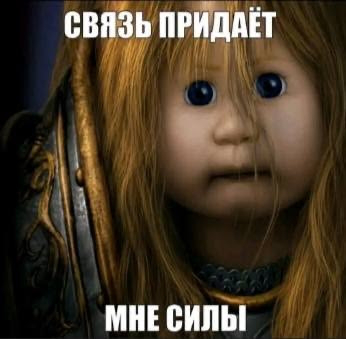

In [46]:
img = Image.open("svyz.jpg")

img